In [2]:
from google.colab import files
uploaded = files.upload()

Saving DOC-20261009-WA0000.xlsx to DOC-20261009-WA0000.xlsx


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_excel("DOC-20261009-WA0000.xlsx", sheet_name="Cleaned_Data")
df["Order Date"] = pd.to_datetime(df["Order Date"])

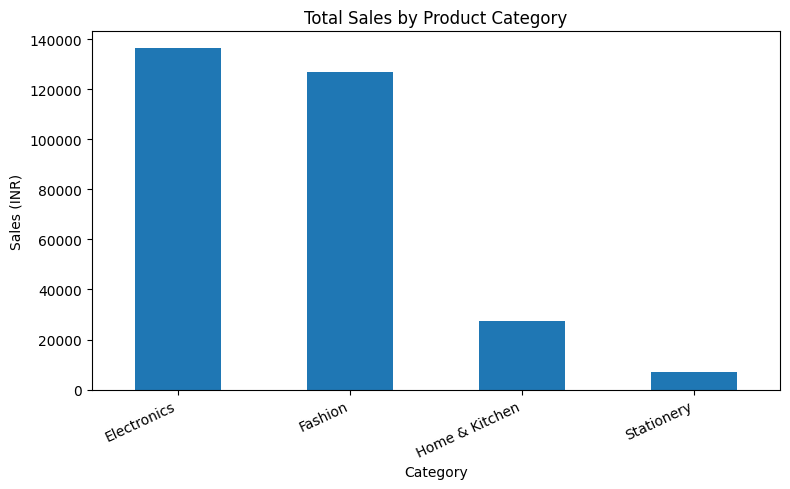

In [4]:
category_sales = df.groupby("Category")["Sales (INR)"].sum().sort_values(ascending=False)
category_sales.plot(kind="bar", figsize=(8, 5), title="Total Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

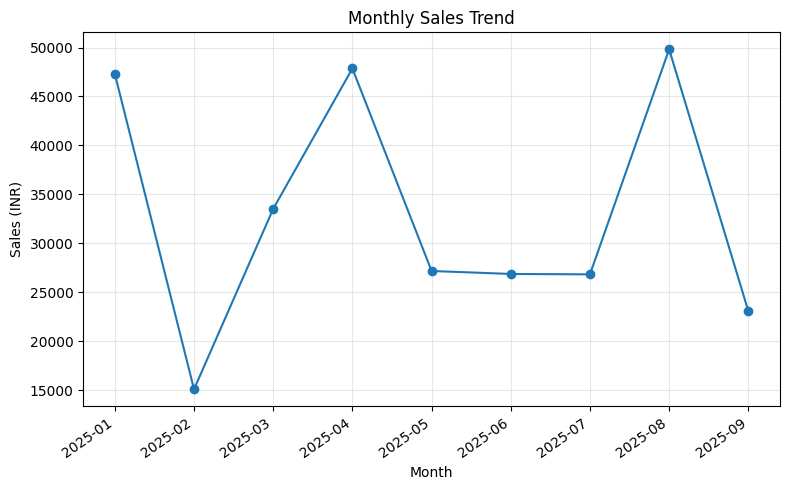

In [5]:
monthly_sales = df.groupby(df["Order Date"].dt.to_period("M"))["Sales (INR)"].sum()
monthly_sales.index = monthly_sales.index.astype(str)
monthly_sales.plot(kind="line", marker="o", figsize=(8, 5), title="Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=35, ha="right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

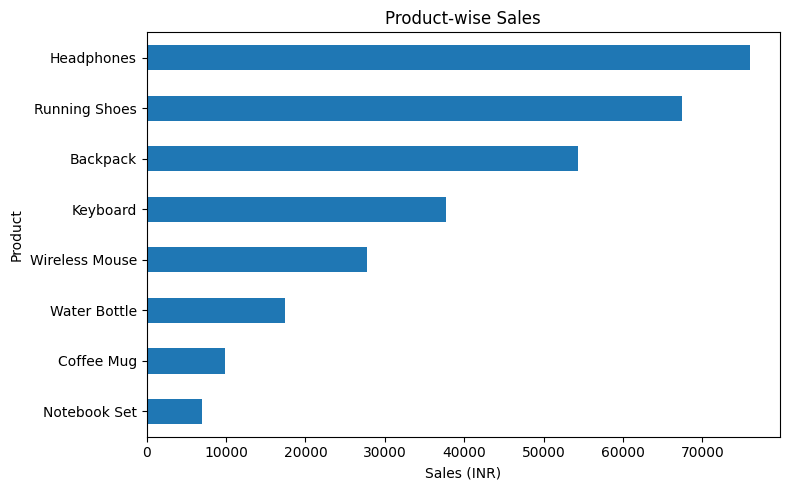

In [6]:
product_sales = df.groupby("Product Name")["Sales (INR)"].sum().sort_values()
product_sales.plot(kind="barh", figsize=(8, 5), title="Product-wise Sales")
plt.xlabel("Sales (INR)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

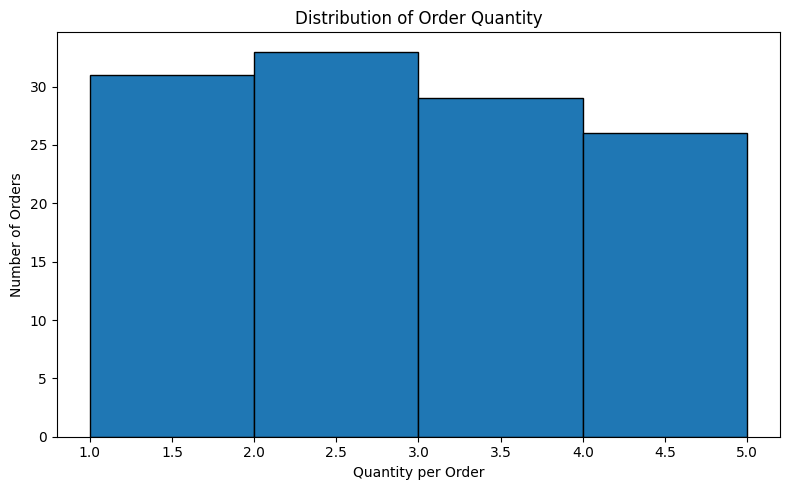

In [7]:
df["Quantity"].plot(
kind="hist",
bins=range(int(df["Quantity"].min()), int(df["Quantity"].max()) + 2),
edgecolor="black",
figsize=(8, 5),
title="Distribution of Order Quantity"
)
plt.xlabel("Quantity per Order")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()